# Day 3 - Exploratory Data Analysis
**Learner Performance Prediction & Early Learning Support Dashboard** | Career Solutions (EduTech)

**Data origin: SYNTHETIC.** Patterns below reflect assumptions built into the generator, not findings about real learners.

**Safety rule:** this EDA uses the **training split only** (900 rows). The validation and test sets are not opened here, so no decision made from these charts can leak information from them.

In [15]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
train = pd.read_csv(ROOT / "data" / "processed" / "train.csv")

NUMERIC = ["attendance_pct", "quiz_average", "assignment_completion_pct",
           "active_learning_minutes", "days_since_last_activity", "practice_attempt_count"]
print(train.shape)
train.head()

(900, 12)


,enrollment_id,learner_group_id,attendance_pct,quiz_average,assignment_completion_pct,active_learning_minutes,days_since_last_activity,practice_attempt_count,course_category,outcome_status,final_score,below_benchmark
0,ENR-00001,LG-00139,66.3,57.7,73.9,121,2,2,Data Analytics,observed,61.7,0
1,ENR-00004,LG-00480,57.7,54.8,28.9,159,4,3,Data Analytics,observed,40.8,1
2,ENR-00005,LG-01252,55.1,45.7,48.7,255,5,2,Data Analytics,observed,34.3,1
3,ENR-00006,LG-00129,67.8,44.4,53.5,93,2,7,Python,observed,49.5,1
4,ENR-00007,LG-00612,79.3,79.1,81.3,218,4,3,Machine Learning,observed,75.5,0


## 1. Overview

In [16]:
train[NUMERIC + ["final_score"]].describe().round(1).T

,count,mean,std,min,25%,50%,75%,max
attendance_pct,900.0,71.3,15.7,16.4,61.9,71.0,81.7,100.0
quiz_average,850.0,59.3,18.5,0.0,47.1,59.4,71.9,100.0
assignment_completion_pct,900.0,68.9,20.2,2.5,54.6,70.0,83.9,100.0
active_learning_minutes,900.0,243.2,123.1,48.0,155.0,217.0,301.2,1088.0
days_since_last_activity,900.0,2.5,2.1,0.0,1.0,2.0,4.0,13.0
practice_attempt_count,900.0,5.8,3.2,0.0,3.0,5.0,8.0,31.0
final_score,900.0,57.3,16.1,4.3,46.9,57.6,68.1,100.0


In [17]:
print("Blank values per column (training split):")
print(train[NUMERIC + ["course_category", "final_score", "below_benchmark"]].isna().sum())

Blank values per column (training split):
attendance_pct                0
quiz_average                 50
assignment_completion_pct     0
active_learning_minutes       0
days_since_last_activity      0
practice_attempt_count        0
course_category               0
final_score                   0
below_benchmark               0
dtype: int64


Only `quiz_average` has blanks. A blank means no quiz was completed before the cutoff, which is different from a genuine score of 0. Blanks stay blank here and are imputed later inside the training pipeline, fitted on training data only.

## 2. Targets

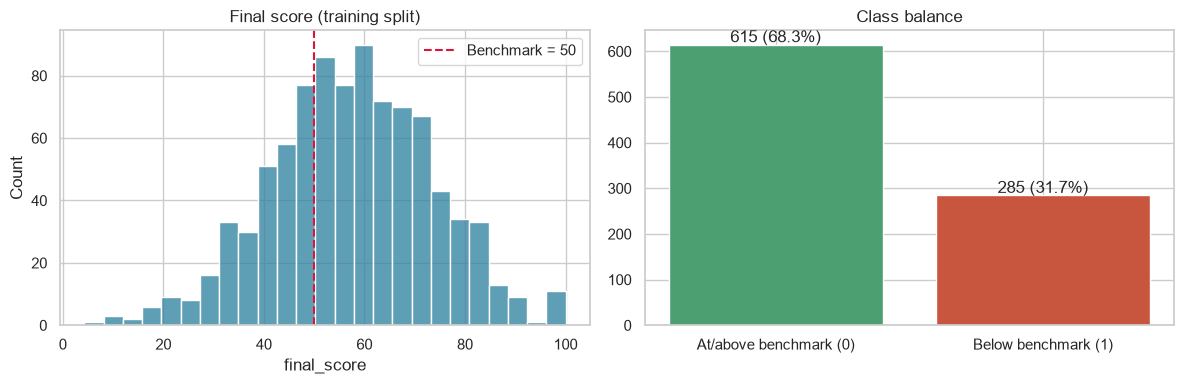

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train["final_score"], bins=25, ax=axes[0], color="#2a7f9e")
axes[0].axvline(50, color="crimson", linestyle="--", label="Benchmark = 50")
axes[0].set_title("Final score (training split)")
axes[0].legend()
counts = train["below_benchmark"].value_counts().sort_index()
axes[1].bar(["At/above benchmark (0)", "Below benchmark (1)"], counts.values, color=["#4c9f70", "#c8553d"])
for i, v in enumerate(counts.values):
    axes[1].text(i, v + 5, f"{v} ({v / len(train):.1%})", ha="center")
axes[1].set_title("Class balance")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_targets.png", dpi=150)
plt.show()

About a third of learners are below the benchmark. The classes are imbalanced but both are well represented, so accuracy alone would be misleading. Precision, recall, F1 and PR-AUC will matter, with a majority-class baseline for comparison.

## 3. Feature distributions

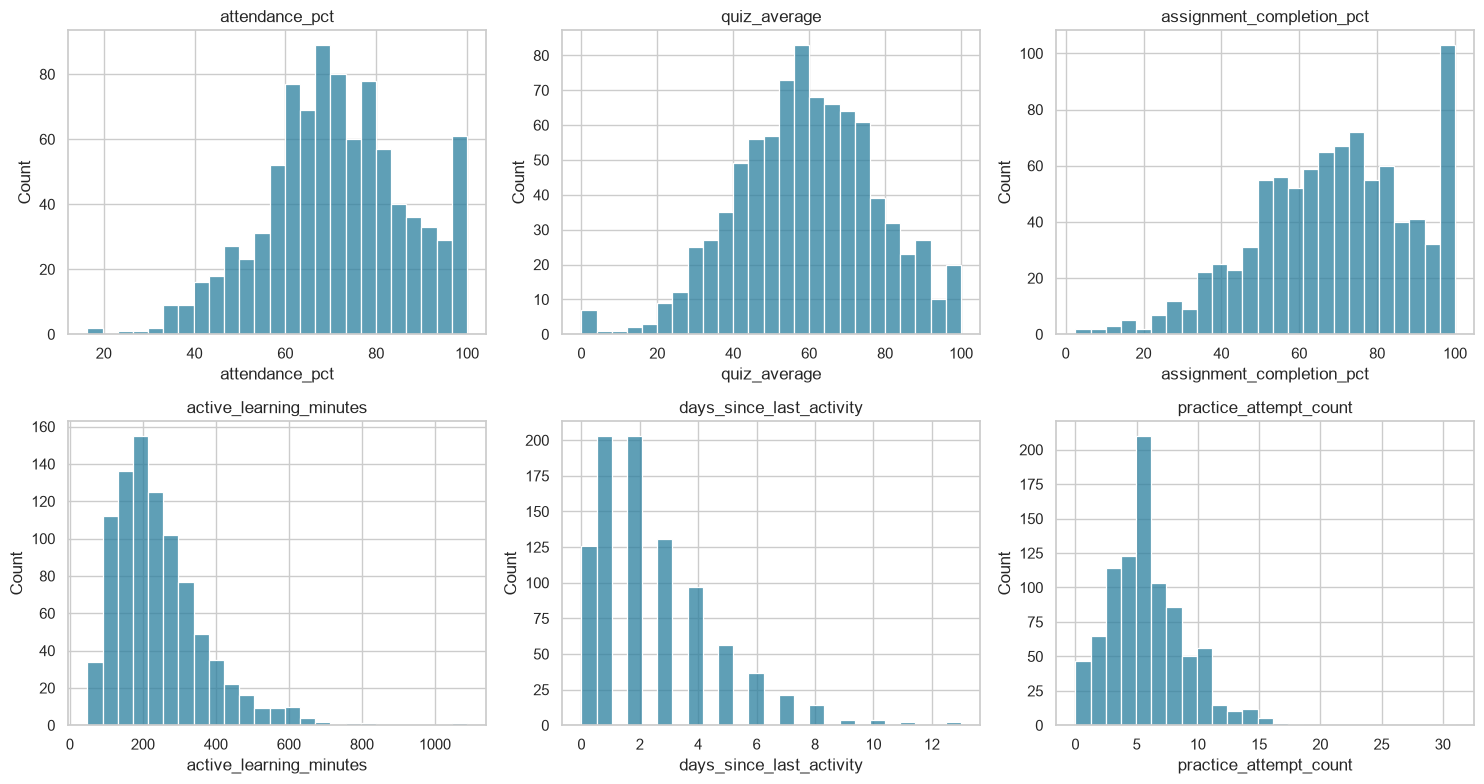

Rows at exactly 100 (range clipping):
  attendance_pct: 42
  assignment_completion_pct: 73
active_learning_minutes skewness: 1.49


In [19]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), NUMERIC):
    sns.histplot(train[col].dropna(), bins=25, ax=ax, color="#2a7f9e")
    ax.set_title(col)
plt.tight_layout()
plt.savefig(FIG_DIR / "02_feature_distributions.png", dpi=150)
plt.show()

print("Rows at exactly 100 (range clipping):")
print("  attendance_pct:", int((train["attendance_pct"] == 100).sum()))
print("  assignment_completion_pct:", int((train["assignment_completion_pct"] == 100).sum()))
print("active_learning_minutes skewness:", round(train["active_learning_minutes"].skew(), 2))

- Percentage features pile up at 100 because of range clipping, which is expected for percentages.
- `active_learning_minutes` is right-skewed, so a few learners have very high activity. Scaling will matter for logistic regression and SVM.
- `days_since_last_activity` is a small count, mostly 0-5 days.

## 4. Course category

,learners,mean_final_score,below_benchmark_rate
course_category,,,
Python,273,58.06,0.30
Data Analytics,218,56.99,0.30
Machine Learning,161,55.74,0.35
Web Development,135,55.77,0.34
SQL,113,60.29,0.30


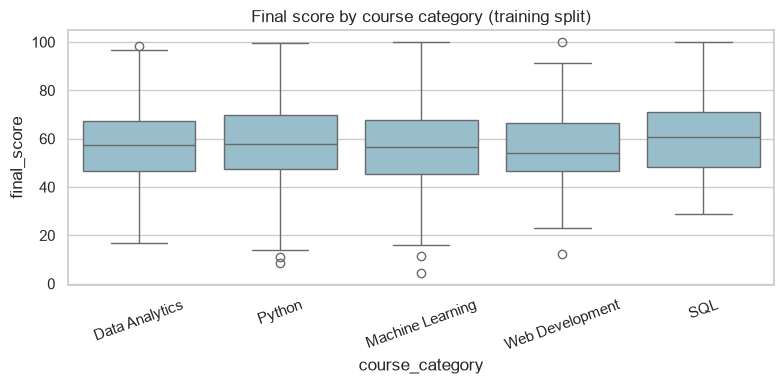

In [20]:
cat = (train.groupby("course_category")
       .agg(learners=("final_score", "size"),
            mean_final_score=("final_score", "mean"),
            below_benchmark_rate=("below_benchmark", "mean"))
       .round(2).sort_values("learners", ascending=False))
display(cat)

fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=train, x="course_category", y="final_score", ax=ax, color="#8fc1d4")
ax.set_title("Final score by course category (training split)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(FIG_DIR / "03_score_by_category.png", dpi=150)
plt.show()

Course categories differ only modestly in average score. Group sizes are small (113 to 273 learners in the training split), so per-category error analysis later must be read cautiously.

## 5. Relationships with the final score

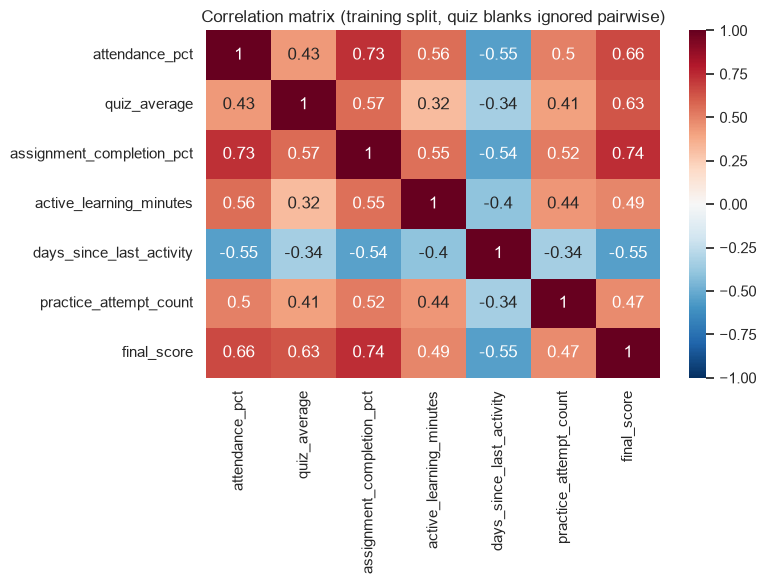

assignment_completion_pct    0.74
attendance_pct               0.66
quiz_average                 0.63
active_learning_minutes      0.49
practice_attempt_count       0.47
days_since_last_activity    -0.55
Name: final_score, dtype: float64

In [21]:
corr = train[NUMERIC + ["final_score"]].corr().round(2)
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation matrix (training split, quiz blanks ignored pairwise)")
plt.tight_layout()
plt.savefig(FIG_DIR / "04_correlation.png", dpi=150)
plt.show()
corr["final_score"].drop("final_score").sort_values(ascending=False)

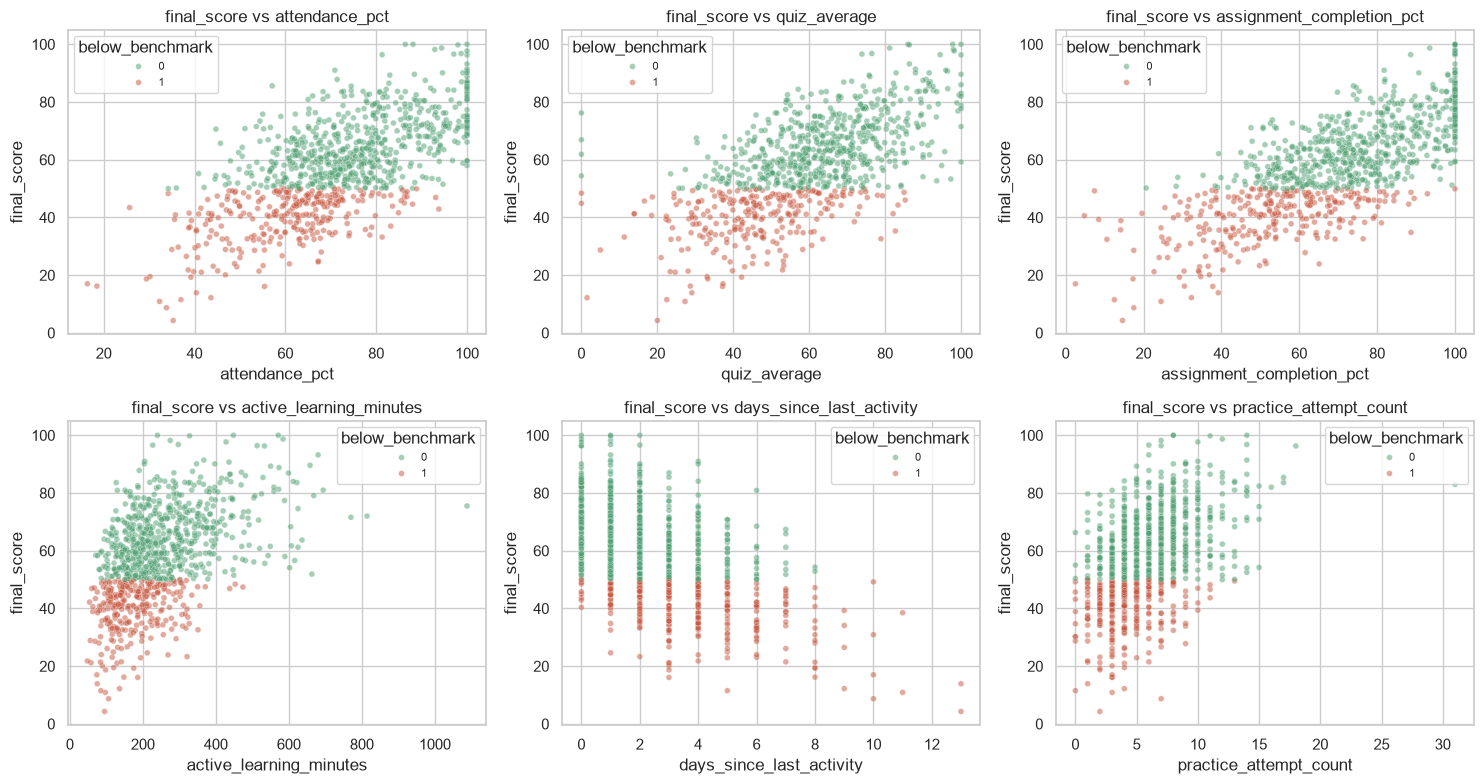

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), NUMERIC):
    sns.scatterplot(data=train, x=col, y="final_score", hue="below_benchmark",
                    palette={0: "#4c9f70", 1: "#c8553d"}, alpha=0.5, s=18, ax=ax)
    ax.set_title(f"final_score vs {col}")
    ax.legend(title="below_benchmark", fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "05_scatter_vs_score.png", dpi=150)
plt.show()

In [23]:
train.groupby("below_benchmark")[NUMERIC].mean().round(1).T.rename(
    columns={0: "at/above benchmark", 1: "below benchmark"})

below_benchmark,at/above benchmark,below benchmark
attendance_pct,76.7,59.8
quiz_average,65.2,45.9
assignment_completion_pct,76.7,51.9
active_learning_minutes,274.2,176.3
days_since_last_activity,1.9,4.0
practice_attempt_count,6.6,4.1


All week-2 features relate to the final score in the expected direction: more attendance, quizzes, assignments, activity and practice go with higher scores, and more days since last activity goes with lower scores. Assignment completion has the strongest linear relationship in this synthetic data. Classes overlap clearly, so perfect separation is not possible.

**Caution:** these are associations in synthetic data. They must not be described as causes of learning outcomes.

## 6. Missing quiz averages

In [24]:
train["quiz_missing"] = train["quiz_average"].isna()
miss = (train.groupby("quiz_missing")
        .agg(learners=("final_score", "size"),
             mean_final_score=("final_score", "mean"),
             below_benchmark_rate=("below_benchmark", "mean"))
        .round(2))
display(miss)
train = train.drop(columns="quiz_missing")

,learners,mean_final_score,below_benchmark_rate
quiz_missing,,,
False,850,57.75,0.30
True,50,50.02,0.52


Learners with no quiz completed before the cutoff have a clearly higher below-benchmark rate (50 learners, so treat this as indicative). Because the blank itself carries information, the preprocessing step should record it, for example with an indicator column, as well as imputing a value. We will decide this on Day 4 using training data only.

## Summary for preprocessing (Day 4)
1. Impute `quiz_average` inside the pipeline, fitted on training data only. Consider a missing-indicator.
2. Standardize numeric features for logistic regression and SVM.
3. One-hot encode `course_category` with unknown categories handled safely.
4. Exclude `enrollment_id`, `learner_group_id`, `outcome_status`, `final_score` and `below_benchmark` from the features.
5. Use a training-mean baseline for the score model and majority-class / prevalence baselines for the classifiers.